Billy York

06/01/2026

# Exploring and Cleaning the Data

In [1]:
from matplotlib import pyplot
import seaborn as sns
import pandas as pd
import psycopg
from psycopg.rows import dict_row

In [2]:
user = 'postgres'
password = 'psql-password'
host = '127.0.0.1'

In [3]:
conn_string = 'postgresql://{}:{}@{}:5432/house_price_prediction_service'.format(user, password, host)
with psycopg.connect(conn_string, row_factory=dict_row) as conn:
    with conn.cursor() as cur:
        cur.execute('SELECT id, event_timestamp, data FROM raw_home_sale_events;')
        # rows will be a list of dicts with the keys 'id', 'event_timestamp', and 'data'
        rows = cur.fetchall()

In [4]:
# Add all the ids to the inner data dictionaries and extract them
json_events = []
for row in rows:
    event = row['data']
    event['id'] = row['id']
    event['event_timestamp'] = row['event_timestamp']
    json_events.append(event)
df = pd.DataFrame.from_records(json_events)

In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 28293 entries, 0 to 28292
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   lat                  28293 non-null  float64       
 1   long                 28293 non-null  float64       
 2   view                 28293 non-null  int64         
 3   grade                28293 non-null  int64         
 4   price                28293 non-null  float64       
 5   floors               28293 non-null  float64       
 6   zipcode              28293 non-null  int64         
 7   bedrooms             28293 non-null  int64         
 8   sqft_lot             28293 non-null  int64         
 9   yr_built             28293 non-null  int64         
 10  bathrooms            28293 non-null  float64       
 11  condition            28293 non-null  int64         
 12  sqft_above           28293 non-null  int64         
 13  sqft_lot15           28293 non-null  int64

# Metadata / Currently Unused Data
The Ids will not be used and will existed simply for the ability to reference raw data, but will be dropped before inference.

The Timestamps will probably not be used per the discussion about date with my professor

The Economic Conditions will be included for the future evolution of the system. 

In [6]:
print(f'# Event Timestamps: {len(set(df['event_timestamp']))}')
print(f'Economic Conditions: {set(df['economic_conditions'])}')
print(f'# Id: {len(set(df['id']))}')

# Event Timestamps: 28293
Economic Conditions: {1.0}
# Id: 28293


### Lat, Long, & Zipcodes
These all describe the properties' locations on a map. Latitude and Longitude should remain floats, but Zipcodes should be a categorical value. There do not seem to be any placeholder values for any of these three columns. 

In [7]:
print(f'# Lats: {len(set(df['lat']))}')
print(f'# Longs: {len(set(df['long']))}')
print(f'# Zipcodes: {len(set(df['zipcode']))}')

# Lats: 5034
# Longs: 752
# Zipcodes: 70


<Axes: ylabel='lat'>

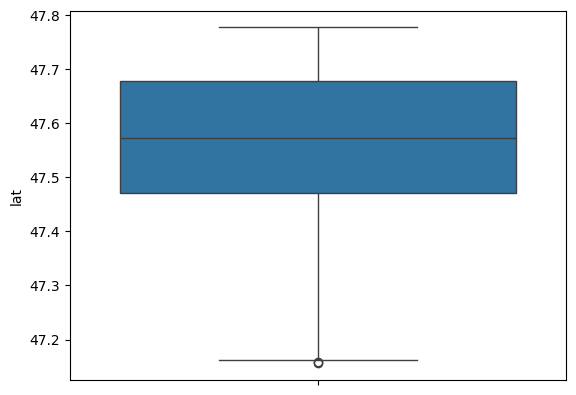

In [8]:
sns.boxplot(data=df['lat'])

<Axes: ylabel='long'>

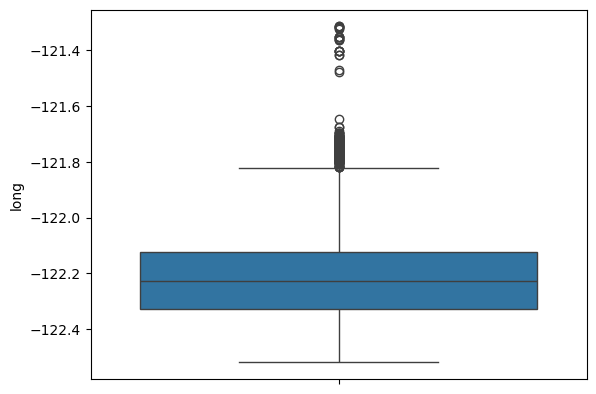

In [9]:
sns.boxplot(data=df['long'])

<Axes: xlabel='lat', ylabel='long'>

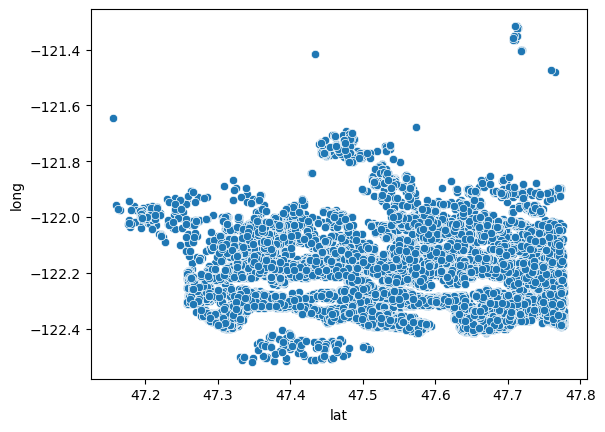

In [10]:
sns.scatterplot(x=df['lat'], y=df['long'])

<Axes: xlabel='zipcode', ylabel='Count'>

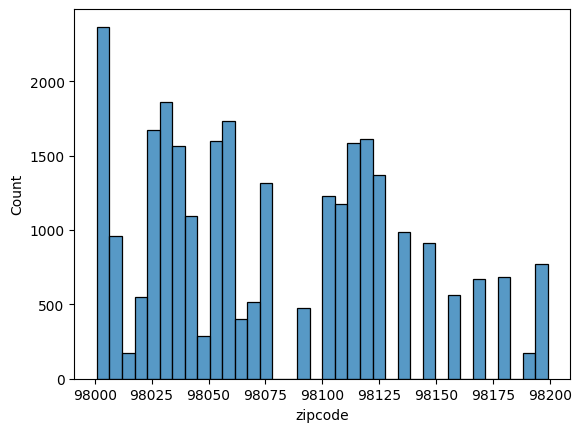

In [11]:
sns.histplot(data=df['zipcode'])

### Square Footage Measurements
These describe the square footages of different parts of the property or the square footages of the 15 closest houses to the property. The square footage of the living space is simply the sum of the above and basement square footages and can likely be removed before inference. All features seem to use 0 as a placeholder value which could be true for the lot and the basement features for properties like condos or houses without basements respectively. The living space being 0, however, does not make sense and will likely require dropping those rows. There are also some extreme outliers, like the property with a lot size of over 1,500,000 square feet, which could be a farm given its living square foot size. A limit on the living size being no greater than 8,000 square feet and a lot size of no greater than 500,000 square feet would capture most of the data while excluding the most extreme outliers, with similar limits on the 15 nearest neighbor features of 5,000 and 200,000 respectively. 

In [12]:
print(f'# Lots Sqft: {len(set(df['sqft_lot']))}')
print(f'# Living Spaces Sqft: {len(set(df['sqft_living']))}')
print(f'# Above Sqft: {len(set(df['sqft_above']))}')
print(f'# Basements Sqft: {len(set(df['sqft_basement']))}')
print(f'# 15 NN Living Spaces Sqft: {len(set(df['sqft_living15']))}')
print(f'# 15 NN Lots Sqft: {len(set(df['sqft_lot15']))}')

# Lots Sqft: 9782
# Living Spaces Sqft: 1038
# Above Sqft: 946
# Basements Sqft: 306
# 15 NN Living Spaces Sqft: 777
# 15 NN Lots Sqft: 8689


<Axes: ylabel='sqft_lot'>

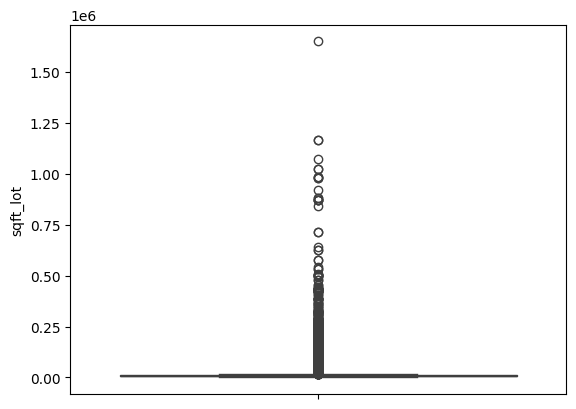

In [13]:
sns.boxplot(data=df['sqft_lot'])

<Axes: ylabel='sqft_living'>

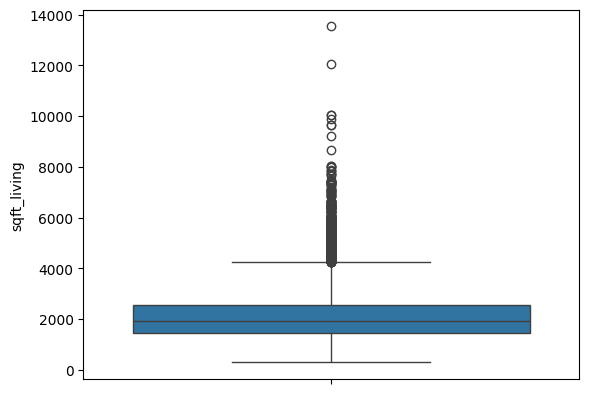

In [14]:
sns.boxplot(data=df['sqft_living'])

<Axes: xlabel='sqft_living', ylabel='sqft_lot'>

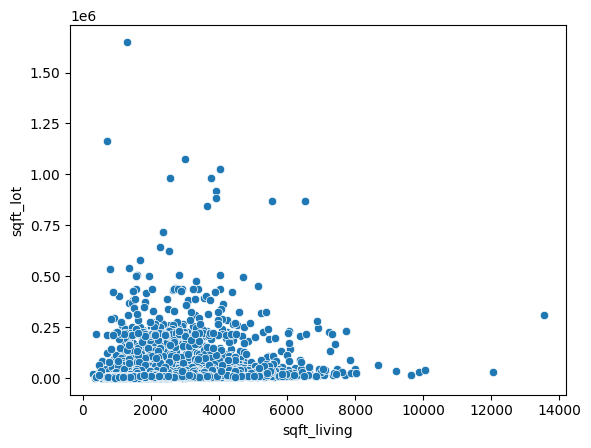

In [15]:
sns.scatterplot(x=df['sqft_living'], y=df['sqft_lot'])

<Axes: ylabel='sqft_above'>

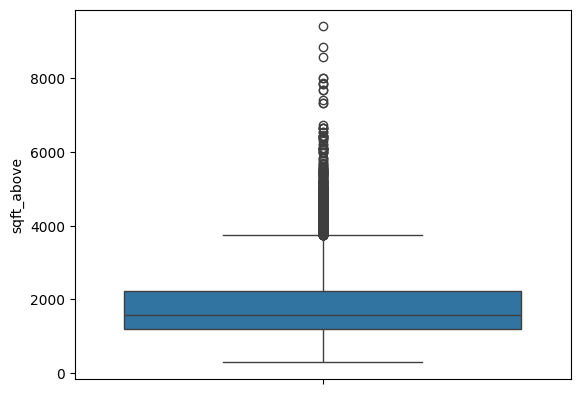

In [16]:
sns.boxplot(data=df['sqft_above'])

<Axes: ylabel='sqft_basement'>

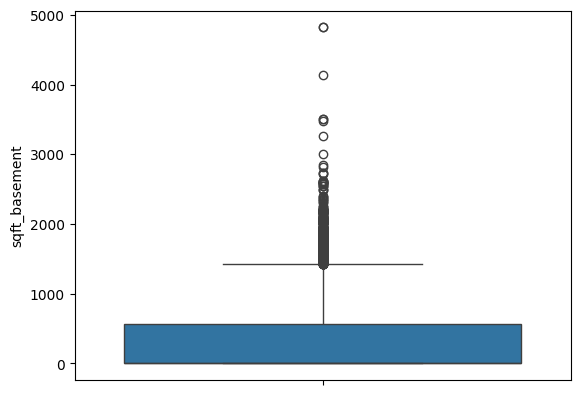

In [17]:
sns.boxplot(data=df['sqft_basement'])

In [18]:
print(set(df['sqft_living'] - (df['sqft_above'] + df['sqft_basement'])))

{0}


<Axes: ylabel='sqft_lot15'>

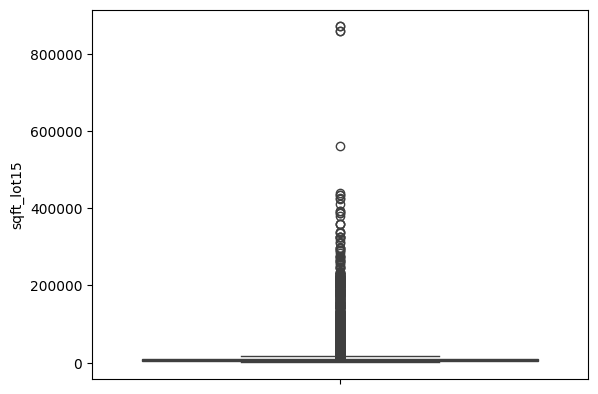

In [19]:
sns.boxplot(data=df['sqft_lot15'])

<Axes: ylabel='sqft_living15'>

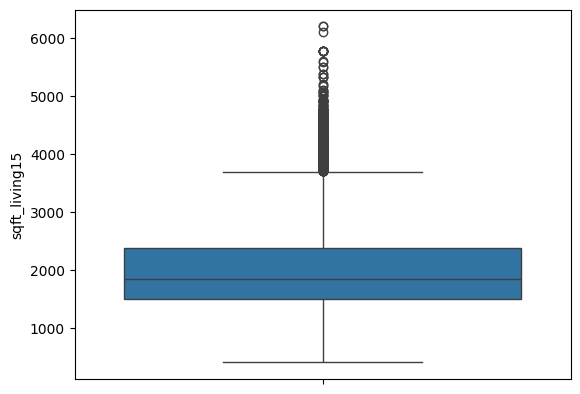

In [20]:
sns.boxplot(data=df['sqft_living15'])

<Axes: xlabel='sqft_living15', ylabel='sqft_lot15'>

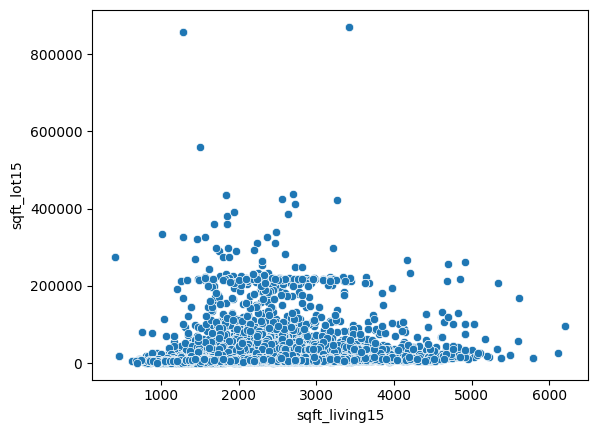

In [21]:
sns.scatterplot(x=df['sqft_living15'], y=df['sqft_lot15'])

### Years Built, Years Last Renovated, Conditions, and Grades
These features can give an overall idea of what shape a house is in, showing the year the property was built, the year the property was last renovated, the condition describing a general condition of the property, and the grade which specifically describes the quality of the construction. The year built feature can remain an integer feature, but the rest should probably be categorical. The year last renovated feature has a placeholder value of 0 to show a house that has not had any major renovations done to it which is what pushed it into a categorical value. There do not appear to be any other placeholder values among the features. Simply due to their rarity, properties with conditions and grades of 1 should probably be dropped so as not to throw off the eventual model. 

In [22]:
print(f'# Years Built: {len(set(df['yr_built']))}')
print(f'# Years Last Renovated: {len(set(df['yr_renovated']))}')
print(f'Grades: {set(df['grade'])}')
print(f'Conditions: {set(df['condition'])}')

# Years Built: 116
# Years Last Renovated: 70
Grades: {1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13}
Conditions: {1, 2, 3, 4, 5}


<Axes: ylabel='yr_built'>

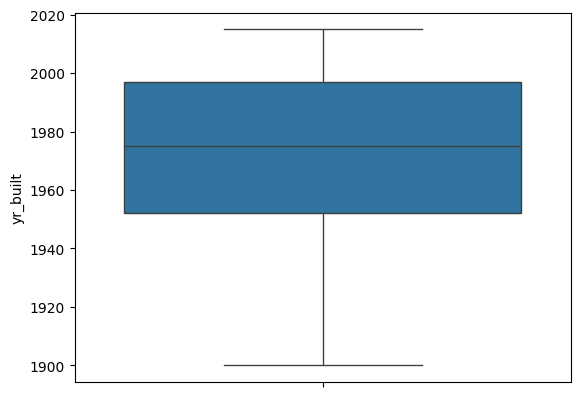

In [23]:
sns.boxplot(data=df['yr_built'])

<Axes: ylabel='yr_renovated'>

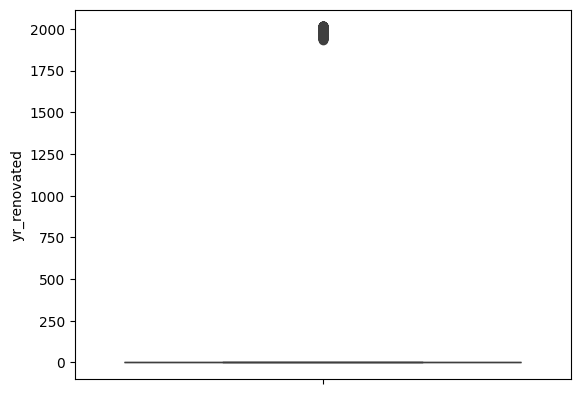

In [24]:
sns.boxplot(data=df['yr_renovated'])

<Axes: ylabel='grade'>

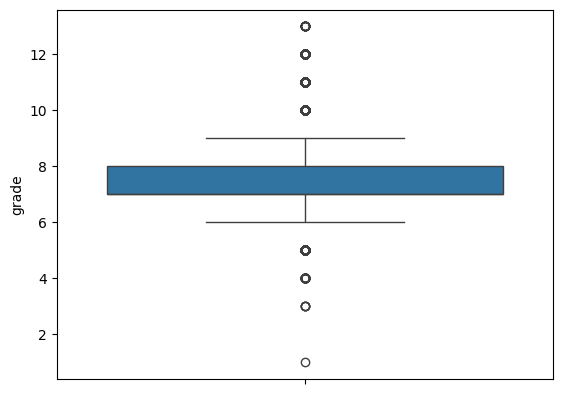

In [25]:
sns.boxplot(data=df['grade'])

<Axes: ylabel='condition'>

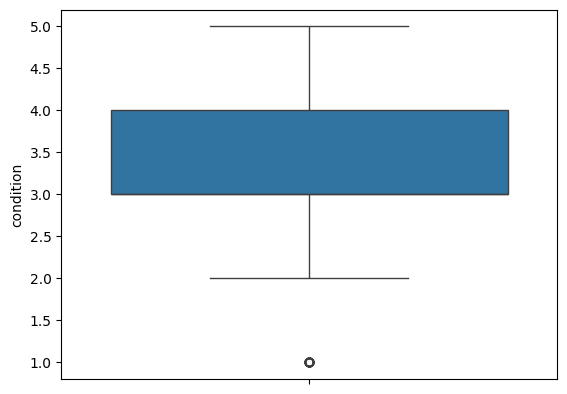

In [26]:
sns.boxplot(data=df['condition'])

### House Features
These features describe the more human elements of the property. The number of bedrooms, bathrooms, and floors. The quality of the view from the property, and if the property is on the waterfront. All of these features should be categorical 

The number of bedrooms uses 0 as a placeholder as I don't believe it's legal to sell a residential property without it having any bedrooms which have their own legal definitions which can vary state to state. Additionally there are some extreme outliers that should be dropped so as not to throw off the accuracy of the model. 6 seems to be a good limit so as to not throw out too much data, just the extremes. 

Bathrooms also use 0 as a placeholder and can be divided into full baths with toilet, sink, shower, and bathtub, three-quarter baths which excludes one of the shower or bathtub, half baths which typically only have a toilet and a sink, and quarter baths which would only have one of the 4 elements. It is unknown if two half baths would equate to one full bath. Regardless, 6 bathrooms looks to be a good limit for removing outliers and the placeholders should be dropped.

Floors can have halves which would describe any level that does not cover the full floor below such as a loft or mezzanine. There are no placeholder values used. There are no values that need to be dropped as there are no outliers in the data.

The overwhelming majority of views are 0s which could be a placeholder value, but the 0-4 scale leads me to believe it could also be a 1-5 rating with 0 based indexing. Regardless, there seems to be some level of prediction power with price in spite of the mix of placeholder and low value, so these should remain as is.

The waterfront feature is a binary feature with 1 representing that a property is on the waterfront and a 0 represents that it is not on the waterfront. Similar to views, most properties are not on the waterfront. However, there does seem to be a real premium on price for waterfront properties, so it will remain as is. 

In [27]:
print(f'Bedrooms: {set(df['bedrooms'])}')
print(f'Bathrooms: {set(df['bathrooms'])}')
print(f'Floors: {set(df['floors'])}')
print(f'Views: {set(df['view'])}')
print(f'Waterfront: {set(df['waterfront'])}')

Bedrooms: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 33, 11}
Bathrooms: {0.75, 1.75, 2.75, 3.0, 2.0, 3.25, 3.5, 1.0, 2.5, 2.25, 4.5, 4.25, 1.5, 4.0, 5.0, 0.5, 3.75, 8.0, 4.75, 5.5, 5.25, 5.75, 6.0, 1.25, 6.5, 0.0, 6.75, 7.75, 7.5, 6.25}
Floors: {1.0, 2.5, 2.0, 3.0, 1.5, 3.5}
Views: {0, 1, 2, 3, 4}
Waterfront: {0, 1}


<Axes: ylabel='bedrooms'>

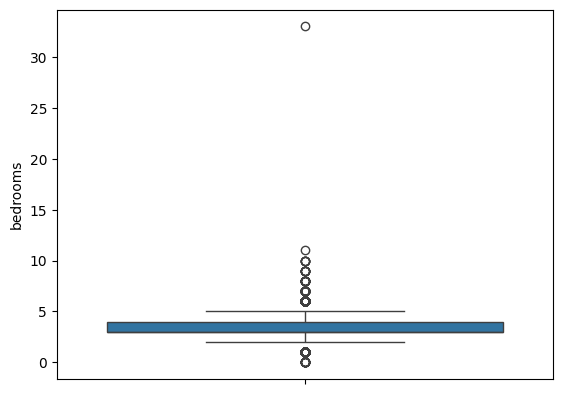

In [28]:
sns.boxplot(data=df['bedrooms'])

<Axes: ylabel='bedrooms'>

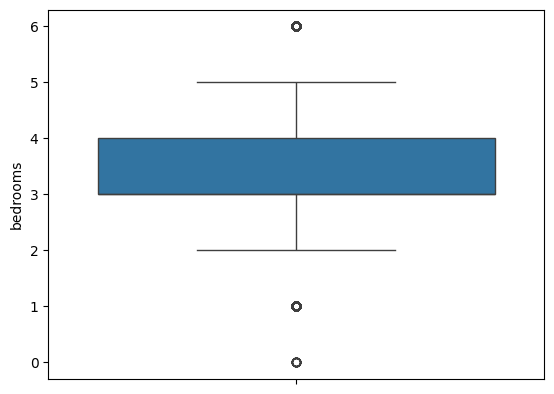

In [29]:
sns.boxplot(data=(df[(df['bedrooms']) <= 6]['bedrooms']))

<Axes: ylabel='bathrooms'>

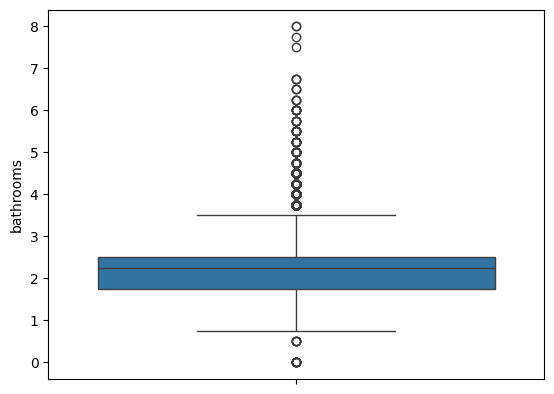

In [30]:
sns.boxplot(data=df['bathrooms'])

<Axes: ylabel='bathrooms'>

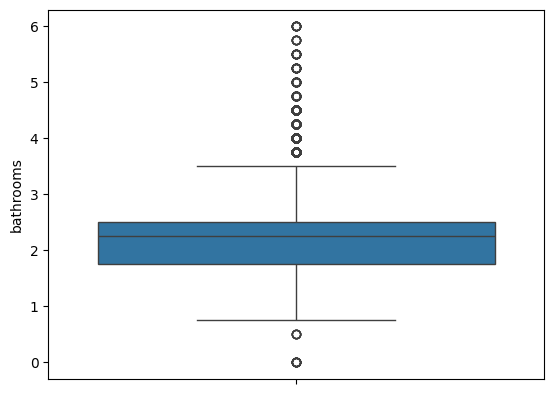

In [31]:
sns.boxplot(data=(df[(df['bathrooms']) <= 6]['bathrooms']))

<Axes: ylabel='floors'>

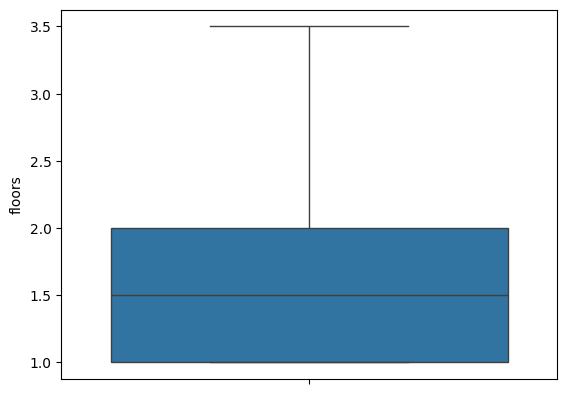

In [32]:
sns.boxplot(data=df['floors'])

<Axes: xlabel='view', ylabel='price'>

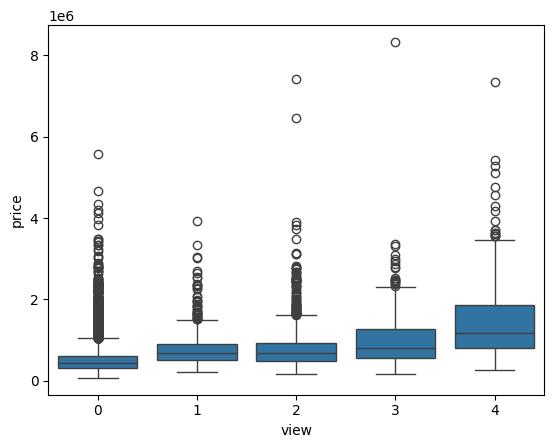

In [33]:
sns.boxplot(data=df, x=df['view'], y=df['price'])

<Axes: xlabel='waterfront', ylabel='price'>

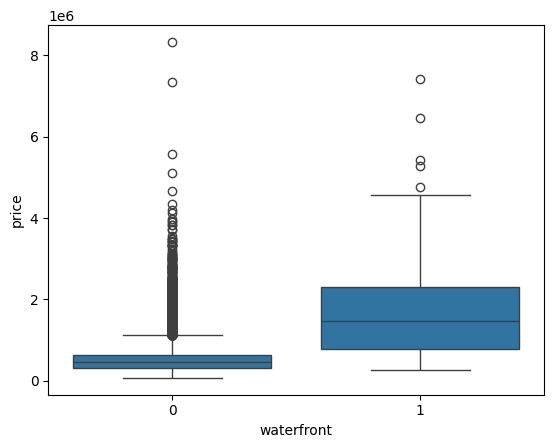

In [34]:
sns.boxplot(data=df, x='waterfront', y='price')

### Price
The last feature is the target feature, price. The price is simply how much money was spent to purchase the home. There does not seem to be any placeholder values for price. It should remain as a float value. Most of the values fall under about $750,000. In order to keep some headroom for inflation, a limit of $4,000,000 seems appropriate. 

In [35]:
print(f'# Prices: {len(set(df['price']))}')

# Prices: 28293


In [36]:
df[df['price'] == 0].head()

,lat,long,view,grade,price,floors,zipcode,bedrooms,sqft_lot,yr_built,...,sqft_above,sqft_lot15,waterfront,sqft_living,yr_renovated,sqft_basement,sqft_living15,event_timestamp,economic_conditions,id


<Axes: ylabel='price'>

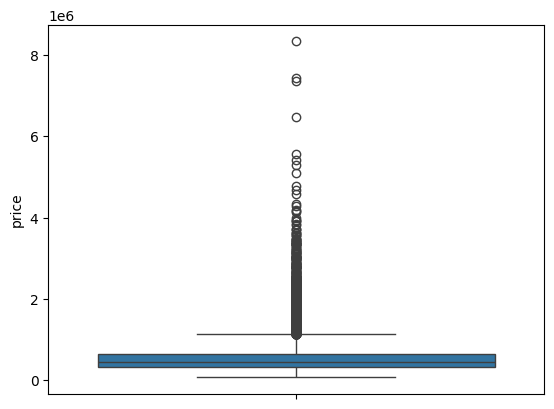

In [37]:
sns.boxplot(data=df['price'])

<Axes: xlabel='price', ylabel='Count'>

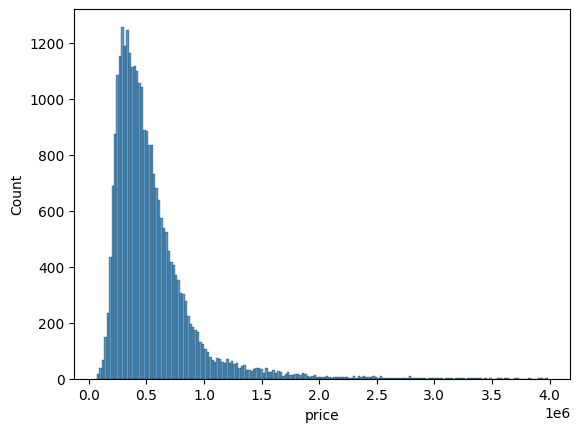

In [38]:
sns.histplot(data=df[df['price'] < 4000000]['price'])

<Axes: ylabel='event_timestamp'>

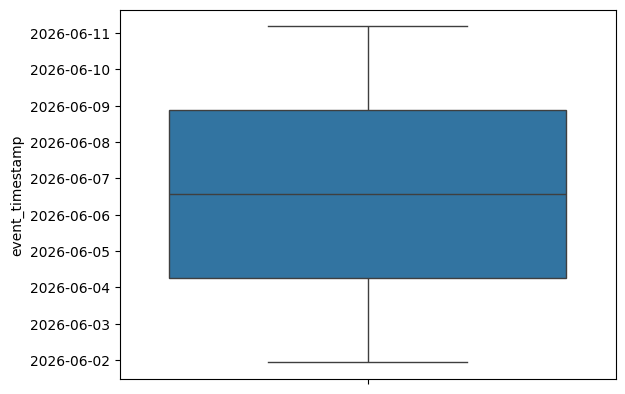

In [39]:
sns.boxplot(data=df['event_timestamp'])

## Column Table

| Name                | Type        | Placeholder Value | Range        | Description                                                                            |
| ------------------- | ----------- | ----------------- | ------------ | -------------------------------------------------------------------------------------- |
| id                  | integer     | N/A               | N/A          | Serial Id from Database                                                                |
| event_timestamp     | datetime    | N/A               | N/A          | Datetime of creation from simulator                                                    |
| economic_conditions | integer     | N/A               | N/A          | Currently unused feature from simulator                                                |
| lat                 | float       | N/A               | N/A          | Latitude of the property                                                               |
| long                | float       | N/A               | N/A          | Longitude of the property                                                              |
| zipcode             | categorical | N/A               | N/A          | US Zipcode of the property                                                             |
| sqft_lot            | integer     | 0                 | (0, 500000]  | Square footage of the lot of the property                                              |
| sqft_living         | integer     | 0                 | (0, 8000]    | Square footage of indoor space (house / apartment)                                     |
| sqft_above          | integer     | 0                 | (0, $\inf$)  | Square footage of indoor space excluding the basement                                  |
| sqft_basement       | integer     | N/A               | [0, $\inf$)  | Square footage of basement                                                             |
| sqft_lot15          | integer     | 0                 | (0, 200000]  | Average Square footage of the lot of 15 Nearest Neighbors of the Property              |
| sqft_living15       | integer     | 0                 | (0, 5000]    | Average Square footage of the indoor space of the 15 Nearest Neighbors of the Property |
| yr_built            | integer     | N/A               | N/A          | Year Property was built                                                                |
| yr_renovated        | categorical | N/A               | N/A          | Year Property was last renovated                                                       |
| condition           | categorical | N/A               | (1, 5]       | General condition of property                                                          |
| grade               | categorical | N/A               | (1, 13]      | Construction quality of property                                                       |
| floors              | categorical | N/A               | N/A          | Number of floors including half floors                                                 |
| bedrooms            | categorical | 0                 | (0, 6]       | Number of bedrooms                                                                     |
| bathrooms           | categorical | 0                 | (0, 6]       | Number of bathrooms                                                                    |
| view                | categorical | N/A               | N/A          | Quality of view                                                                        |
| waterfront          | binary      | N/A               | [0, 1]       | Binary feature describing if property is on waterfront                                 |
| price               | float       | N/A               | (0, 4000000) | Price of sale of property                                                              |

## Inferred Schema

```sql
CREATE TABLE home_sale_event (
    lat NUMERIC NOT NULL,
    long NUMERIC NOT NULL,
    zipcode INTEGER NOT NULL,
    sqft_lot INTEGER NOT NULL CHECK (sqft_lot > 0 AND sqft_lot <= 500000),
    sqft_living INTEGER NOT NULL CHECK (sqft_living > 0 AND sqft_living <= 8000),
    sqft_above INTEGER NOT NULL CHECK (sqft_above > 0),
    sqft_basement INTEGER NOT NULL,
    sqft_lot15 INTEGER NOT NULL CHECK (sqft_lot15 > 0 AND sqft_lot15 <= 200000),
    sqft_living15 INTEGER NOT NULL CHECK (sqft_living15 > 0 AND sqft_living <= 5000),
    yr_built INTEGER NOT NULL,
    yr_renovated INTEGER NOT NULL,
    condition INTEGER NOT NULL CHECK (condition > 1),
    grade INTEGER NOT NULL CHECK (grade > 1),
    floors FLOAT NOT NULL,
    bedrooms INTEGER NOT NULL CHECK (bedrooms > 0 AND bedrooms <= 6),
    bathrooms FLOAT NOT NULL CHECK (bathrooms > 0 AND bathrooms <= 6),
    view INTEGER NOT NULL,
    waterfront INTEGER NOT NULL,
    price NUMERIC NOT NULL,
    event_timestamp DATETIME NOT NULL,
    economic_conditions INTEGER NOT NULL,
    id INTEGER PRIMARY KEY,
);
```

## Prepare and Upload Complementary Data

In [40]:
raw_population_df = pd.read_csv("../data/population_by_zip_2010.csv",
		usecols=["population", "zipcode"],
		dtype={ "zipcode" : str })
population_df = raw_population_df.groupby(by='zipcode', as_index=False).sum()
population_df.head()

,zipcode,population
0,00602,124560
1,00603,164067
2,00606,19845
3,00610,87048
4,00612,201030


In [41]:
raw_school_df = pd.read_csv("../data/Public_Schools.csv",
		usecols=["ZIP", "LEVEL_"],
		dtype= { "ZIP" : str })
school_df = pd.get_dummies(data=raw_school_df, prefix_sep='', columns=['LEVEL_'], dtype='int64').groupby(by='ZIP', as_index=False).sum()
school_df['total_schools'] = school_df['LEVEL_High'] + school_df['LEVEL_Middle'] + school_df['LEVEL_Primary'] + school_df['LEVEL_Other'] + school_df['LEVEL_Unknown']
school_df.head()

,ZIP,LEVEL_High,LEVEL_Middle,LEVEL_Other,LEVEL_Primary,LEVEL_Unknown,total_schools
0,00601,0,2,0,7,0,9
1,00602,2,1,5,12,0,20
2,00603,1,4,1,10,0,16
3,00604,0,0,2,0,0,2
4,00605,2,0,0,6,0,8


In [42]:
with psycopg.connect(conn_string) as conn:
    with conn.cursor() as cur:
        for row in population_df.to_dict(orient="records"):
            cur.execute("""INSERT INTO cleaned_zipcode_populations
                (zipcode, population)
                VALUES
                (%(zipcode)s, %(population)s);""",
        row)
    conn.commit()

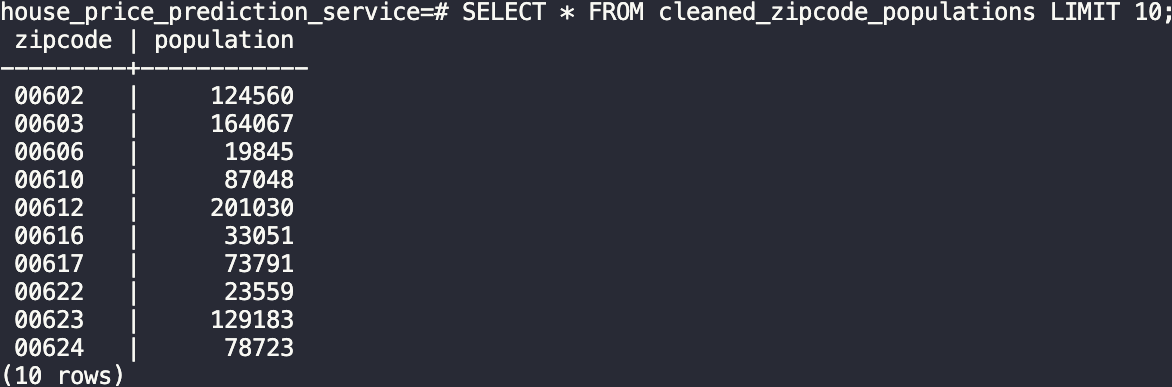

In [43]:
with psycopg.connect(conn_string) as conn:
    with conn.cursor() as cur:
        for row in school_df.to_dict(orient="records"):
            cur.execute("""INSERT INTO cleaned_zipcode_public_schools
                (zipcode, high_schools, middle_schools, primary_schools, other_schools, unknown_schools, total_schools)
                VALUES
                (%(ZIP)s, %(LEVEL_High)s, %(LEVEL_Middle)s, %(LEVEL_Primary)s, %(LEVEL_Other)s, %(LEVEL_Unknown)s, %(total_schools)s);""",
        row)
    conn.commit()

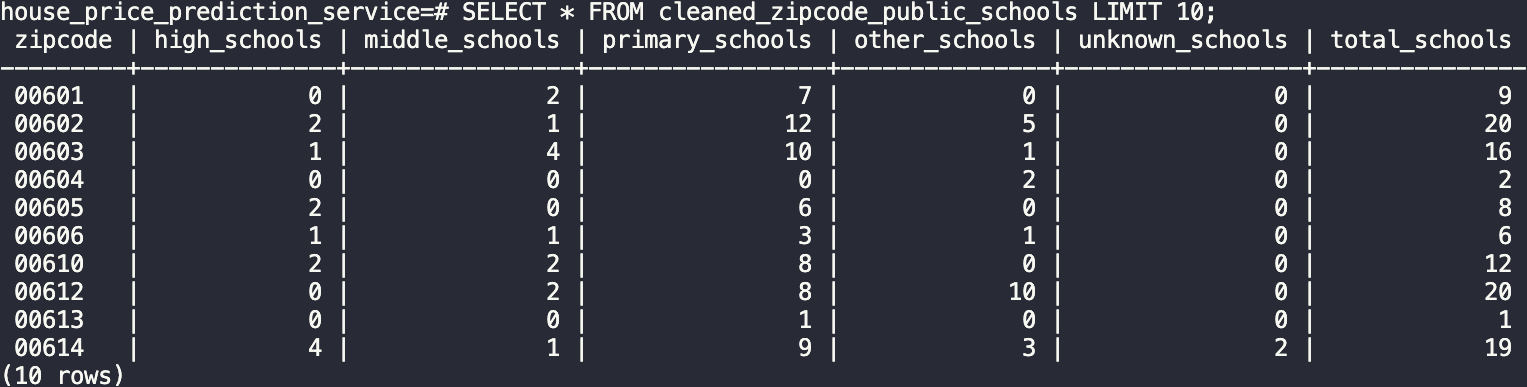